In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn

In [2]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_train_sentimantal_data.csv to cleaned_train_sentimantal_data.csv


In [3]:
import pandas as pd
import os

filename = next(iter(uploaded.keys()))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (27480, 4)

Column names:
['textID', 'text', 'sentiment', 'cleaned_text']

First five rows:


,textID,text,sentiment,cleaned_text
0,cb774db0d1,"I`d have responded, if I were going",neutral,d respond go
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,negative,sooo sad miss san diego
2,088c60f138,my boss is bullying me...,negative,boss bully
3,9642c003ef,what interview! leave me alone,negative,interview leave
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...",negative,son not release buy



Missing values:
textID            0
text              0
sentiment         0
cleaned_text    124
dtype: int64


In [4]:
import re
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from collections import Counter

# Automatically identify likely columns
text_candidates = [
    "text", "cleaned_text", "review", "sentence",
    "tweet", "content", "comment", "message"
]
label_candidates = [
    "sentiment", "label", "target", "polarity",
    "class", "category"
]

def find_column(candidates, columns):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

TEXT_COL = find_column(text_candidates, df.columns)
LABEL_COL = find_column(label_candidates, df.columns)

print("Detected text column:", TEXT_COL)
print("Detected label column:", LABEL_COL)

# If either is None, set it manually after inspecting df.columns.
# Example:
# TEXT_COL = "Cleaned_Text"
# LABEL_COL = "Sentiment"

if TEXT_COL is None or LABEL_COL is None:
    raise ValueError(
        "Could not identify columns automatically. "
        "Set TEXT_COL and LABEL_COL using the printed column names."
    )

data = df[[TEXT_COL, LABEL_COL]].dropna().copy()
data[TEXT_COL] = data[TEXT_COL].astype(str).str.strip()
data = data[data[TEXT_COL] != ""]

# Encode sentiment labels
encoder = LabelEncoder()
data["encoded_label"] = encoder.fit_transform(
    data[LABEL_COL].astype(str)
)

texts = data[TEXT_COL].tolist()
labels = data["encoded_label"].to_numpy()

NUM_CLASSES = len(encoder.classes_)

print("Sentiment classes:", list(encoder.classes_))
print("Number of classes:", NUM_CLASSES)
print("\nClass distribution:")
print(data[LABEL_COL].value_counts())

# Stratified split preserves class proportions where possible
X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("\nTraining samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

Detected text column: text
Detected label column: sentiment
Sentiment classes: ['negative', 'neutral', 'positive']
Number of classes: 3

Class distribution:
sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64

Training samples: 21984
Testing samples: 5496


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

# Build vocabulary from training text only
word_counts = Counter(
    word
    for text in X_train_text
    for word in tokenize(text)
)

PAD_IDX = 0
UNK_IDX = 1
MAX_VOCAB = 30000

vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}

for word, count in word_counts.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

MAX_LEN = 150

def encode_text(text):
    tokens = tokenize(text)[:MAX_LEN]
    ids = [vocab.get(word, UNK_IDX) for word in tokens]
    return ids if ids else [UNK_IDX]

class SentimentDataset(Dataset):
    def __init__(self, texts, labels):
        self.sequences = [encode_text(t) for t in texts]
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

def collate_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor(
        [len(seq) for seq in sequences], dtype=torch.long
    )
    sequences = [
        torch.tensor(seq, dtype=torch.long) for seq in sequences
    ]
    padded = pad_sequence(
        sequences, batch_first=True, padding_value=PAD_IDX
    )
    return padded, lengths, torch.stack(labels)

train_dataset = SentimentDataset(X_train_text, y_train)
test_dataset = SentimentDataset(X_test_text, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True,
    collate_fn=collate_batch
)
test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False,
    collate_fn=collate_batch
)

print("Vocabulary size:", len(vocab))
print("Maximum sequence length:", MAX_LEN)

Using device: cpu
Vocabulary size: 23005
Maximum sequence length: 150


In [6]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

class SentimentRNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_layers=1,
        rnn_type="LSTM",
        num_classes=2,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=PAD_IDX
        )

        rnn_type = rnn_type.upper()

        if rnn_type == "RNN":
            self.rnn = nn.RNN(
                embedding_dim, hidden_dim,
                num_layers=num_layers,
                batch_first=True,
                nonlinearity="tanh",
                dropout=dropout if num_layers > 1 else 0
            )
        elif rnn_type == "LSTM":
            self.rnn = nn.LSTM(
                embedding_dim, hidden_dim,
                num_layers=num_layers,
                batch_first=True,
                dropout=dropout if num_layers > 1 else 0
            )
        elif rnn_type == "GRU":
            self.rnn = nn.GRU(
                embedding_dim, hidden_dim,
                num_layers=num_layers,
                batch_first=True,
                dropout=dropout if num_layers > 1 else 0
            )
        else:
            raise ValueError("Choose RNN, LSTM, or GRU")

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x, lengths):
        embedded = self.embedding(x)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        # LSTM returns (hidden state, cell state)
        if isinstance(hidden, tuple):
            hidden = hidden[0]

        # Final layer's final hidden state
        final_hidden = hidden[-1]

        return self.fc(self.dropout(final_hidden))

# Test the model
model = SentimentRNN(
    vocab_size=len(vocab),
    rnn_type="LSTM",
    num_layers=1,
    num_classes=NUM_CLASSES
).to(device)

sample_x, sample_lengths, _ = next(iter(train_loader))
sample_output = model(sample_x.to(device), sample_lengths)

print("Output shape:", sample_output.shape)
print(model)

Output shape: torch.Size([64, 3])
SentimentRNN(
  (embedding): Embedding(23005, 128, padding_idx=0)
  (rnn): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [7]:
import copy
from sklearn.metrics import accuracy_score

def evaluate_loss(model, loader, criterion):
    model.eval()
    total_loss = 0
    total_samples = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for x, lengths, y in loader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x, lengths)
            loss = criterion(logits, y)

            total_loss += loss.item() * len(y)
            total_samples += len(y)

            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_labels.extend(y.cpu().tolist())

    return (
        total_loss / max(total_samples, 1),
        accuracy_score(all_labels, all_preds)
    )

def train_model(
    rnn_type="LSTM",
    num_layers=1,
    epochs=25,
    learning_rate=0.001
):
    model = SentimentRNN(
        vocab_size=len(vocab),
        embedding_dim=128,
        hidden_dim=128,
        num_layers=num_layers,
        rnn_type=rnn_type,
        num_classes=NUM_CLASSES,
        dropout=0.3
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_accuracy = -1
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        total_samples = 0

        for x, lengths, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            logits = model(x, lengths)
            loss = criterion(logits, y)
            loss.backward()

            # Helps prevent exploding gradients
            nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            total_loss += loss.item() * len(y)
            total_samples += len(y)

        train_loss = total_loss / max(total_samples, 1)
        val_loss, val_accuracy = evaluate_loss(
            model, test_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {val_loss:.4f} | "
            f"Test Accuracy: {val_accuracy:.4f}"
        )

    model.load_state_dict(best_state)
    return model, history

# First experiment: one-layer LSTM
lstm_model, lstm_history = train_model(
    rnn_type="LSTM",
    num_layers=1,
    epochs=25
)

Epoch 01/25 | Train Loss: 0.9375 | Test Loss: 0.8244 | Test Accuracy: 0.6321
Epoch 02/25 | Train Loss: 0.7346 | Test Loss: 0.7751 | Test Accuracy: 0.6712
Epoch 03/25 | Train Loss: 0.6155 | Test Loss: 0.7592 | Test Accuracy: 0.6754
Epoch 04/25 | Train Loss: 0.4993 | Test Loss: 0.8320 | Test Accuracy: 0.6732
Epoch 05/25 | Train Loss: 0.3927 | Test Loss: 0.9107 | Test Accuracy: 0.6647
Epoch 06/25 | Train Loss: 0.2954 | Test Loss: 0.9912 | Test Accuracy: 0.6712
Epoch 07/25 | Train Loss: 0.2195 | Test Loss: 1.0805 | Test Accuracy: 0.6736
Epoch 08/25 | Train Loss: 0.1542 | Test Loss: 1.2659 | Test Accuracy: 0.6539
Epoch 09/25 | Train Loss: 0.1156 | Test Loss: 1.3461 | Test Accuracy: 0.6616
Epoch 10/25 | Train Loss: 0.0842 | Test Loss: 1.6469 | Test Accuracy: 0.6503
Epoch 11/25 | Train Loss: 0.0596 | Test Loss: 1.6808 | Test Accuracy: 0.6554
Epoch 12/25 | Train Loss: 0.0535 | Test Loss: 1.7708 | Test Accuracy: 0.6567
Epoch 13/25 | Train Loss: 0.0448 | Test Loss: 1.9774 | Test Accuracy: 0.6510

In [8]:
experiments = {}
comparison_results = []

for rnn_type in ["RNN", "LSTM", "GRU"]:
    for layers in [1, 2]:
        print("\n" + "=" * 55)
        print(f"Training {rnn_type} with {layers} layer(s)")
        print("=" * 55)

        trained_model, history = train_model(
            rnn_type=rnn_type,
            num_layers=layers,
            epochs=25
        )

        key = f"{rnn_type}_{layers}_layer"
        experiments[key] = {
            "model": trained_model,
            "history": history,
            "type": rnn_type,
            "layers": layers
        }

        comparison_results.append({
            "Architecture": rnn_type,
            "Layers": layers,
            "Best monitored accuracy": max(
                history["val_accuracy"]
            ),
            "Final training loss": history["train_loss"][-1]
        })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)


Training RNN with 1 layer(s)
Epoch 01/25 | Train Loss: 1.0170 | Test Loss: 0.9386 | Test Accuracy: 0.5448
Epoch 02/25 | Train Loss: 0.8802 | Test Loss: 0.8646 | Test Accuracy: 0.5908
Epoch 03/25 | Train Loss: 0.7669 | Test Loss: 0.8311 | Test Accuracy: 0.6346
Epoch 04/25 | Train Loss: 0.6740 | Test Loss: 0.8155 | Test Accuracy: 0.6479
Epoch 05/25 | Train Loss: 0.5854 | Test Loss: 0.8531 | Test Accuracy: 0.6483
Epoch 06/25 | Train Loss: 0.5100 | Test Loss: 0.8830 | Test Accuracy: 0.6468
Epoch 07/25 | Train Loss: 0.4459 | Test Loss: 0.9324 | Test Accuracy: 0.6578
Epoch 08/25 | Train Loss: 0.3861 | Test Loss: 0.9970 | Test Accuracy: 0.6588
Epoch 09/25 | Train Loss: 0.3314 | Test Loss: 1.0748 | Test Accuracy: 0.6477
Epoch 10/25 | Train Loss: 0.2836 | Test Loss: 1.1889 | Test Accuracy: 0.6412
Epoch 11/25 | Train Loss: 0.2392 | Test Loss: 1.2755 | Test Accuracy: 0.6477
Epoch 12/25 | Train Loss: 0.1988 | Test Loss: 1.4327 | Test Accuracy: 0.6225
Epoch 13/25 | Train Loss: 0.1648 | Test Loss: 

,Architecture,Layers,Best monitored accuracy,Final training loss
0,RNN,1,0.658843,0.038375
1,RNN,2,0.660480,0.059352
2,LSTM,1,0.676310,0.013533
3,LSTM,2,0.697416,0.023539
4,GRU,1,0.684680,0.022072
5,GRU,2,0.695779,0.021239


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def get_predictions(model, loader):
    model.eval()
    predictions = []
    actual = []

    with torch.no_grad():
        for x, lengths, y in loader:
            logits = model(x.to(device), lengths)
            predictions.extend(
                logits.argmax(dim=1).cpu().tolist()
            )
            actual.extend(y.tolist())

    return np.array(actual), np.array(predictions)

metric_rows = []

for key, exp in experiments.items():
    y_true, y_pred = get_predictions(
        exp["model"], test_loader
    )

    metric_rows.append({
        "Model": key,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro",
            zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro",
            zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_true, y_pred, average="macro",
            zero_division=0
        )
    })

metrics_df = pd.DataFrame(metric_rows)
display(
    metrics_df.sort_values(
        "F1-score (Macro)", ascending=False
    ).round(4)
)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,LSTM_2_layer,0.6974,0.7063,0.6960,0.7003
5,GRU_2_layer,0.6958,0.7114,0.6923,0.6993
4,GRU_1_layer,0.6847,0.7011,0.6827,0.6889
2,LSTM_1_layer,0.6763,0.6879,0.6732,0.6790
1,RNN_2_layer,0.6605,0.6737,0.6567,0.6631
0,RNN_1_layer,0.6588,0.6935,0.6440,0.6563


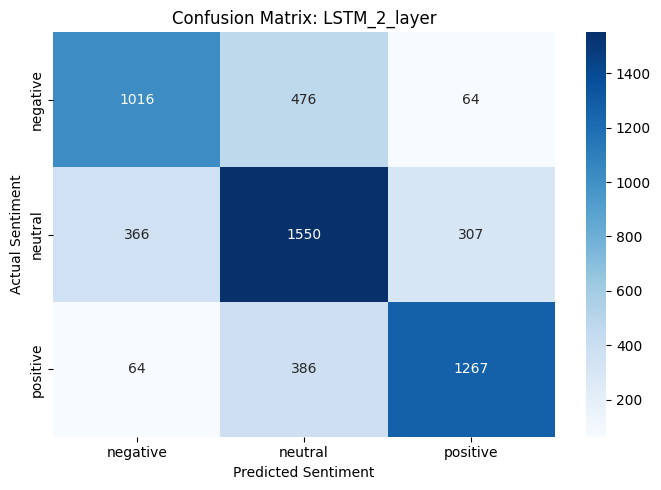

Best model: LSTM_2_layer

Classification Report:
              precision    recall  f1-score   support

    negative       0.70      0.65      0.68      1556
     neutral       0.64      0.70      0.67      2223
    positive       0.77      0.74      0.76      1717

    accuracy                           0.70      5496
   macro avg       0.71      0.70      0.70      5496
weighted avg       0.70      0.70      0.70      5496



In [10]:
best_key = metrics_df.sort_values(
    "F1-score (Macro)", ascending=False
).iloc[0]["Model"]

best_model = experiments[best_key]["model"]

y_true, y_pred = get_predictions(best_model, test_loader)

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title(f"Confusion Matrix: {best_key}")
plt.tight_layout()
plt.show()

print("Best model:", best_key)
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=[str(c) for c in encoder.classes_],
    zero_division=0
))

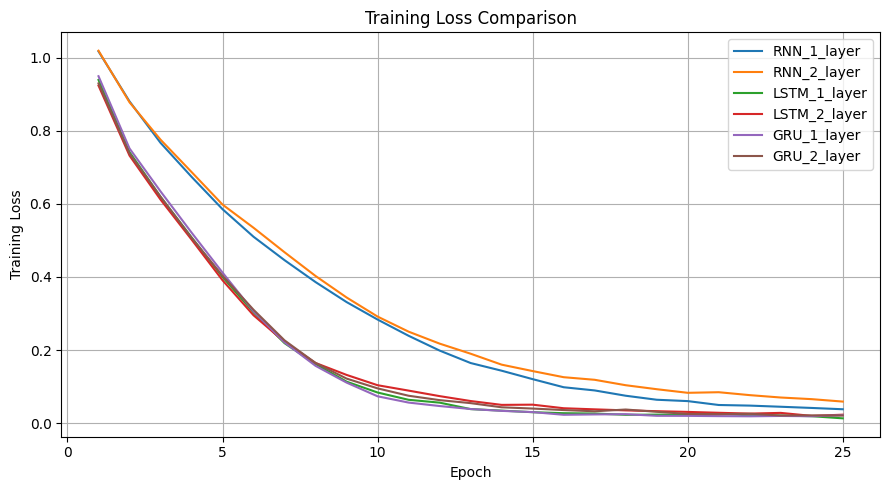

In [11]:
plt.figure(figsize=(9, 5))

for key, exp in experiments.items():
    plt.plot(
        range(1, 26),
        exp["history"]["train_loss"],
        label=key
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
metrics_df.to_csv(
    "RNN_Assignment_Metrics.csv", index=False
)

torch.save(
    best_model.state_dict(),
    "best_sentiment_model.pth"
)

print("Files saved successfully.")

Files saved successfully.


In [13]:
from google.colab import files

files.download("RNN_Assignment_Metrics.csv")
files.download("best_sentiment_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>